# Streaming Conformalized EMM: robustness run with gradient boosting

Code for the paper *Streaming Conformalized Exceptional Model Mining: Finding, Monitoring and Repairing Under-Covered Subgroups in an ICU Sepsis Stream* (2AMM20, TU/e).

This notebook is the same code as `01_main_run_logreg_beam.ipynb`, run with `MODEL_TYPE = "hgb"` (gradient boosting) and `SEARCH = "grid"`. Its saved outputs are the "second base model" check in paper Section 7.5: AUROC and AUPRC (Section 6), septic-hour coverage under ACI (Section 8), RAUL versus the coverage gap (Section 9b), monitoring (Section 10) and repair (Section 12). The main experiment and Figure 1 of the paper are in `01_main_run_logreg_beam.ipynb`.

**Data.** PhysioNet/CinC 2019 sepsis challenge, training sets A and B (40,336 ICU stays from two hospital systems). The data are public at https://physionet.org/content/challenge-2019/1.0.0/ and are not included with the code. In Google Colab, Section 2 mounts Google Drive and downloads both training sets there (`MyDrive/physionet.org/files/challenge-2019/1.0.0/training`) if they are not present yet; the first download takes a while. Outside Colab, download them yourself and set `DATA_PATH` in Section 1 (or the environment variable `SEPSIS_DATA_PATH`) to the folder that contains `training_setA` and `training_setB`.

**How to run.** Open the notebook in Google Colab and use *Runtime → Run all*. The first run installs `river` (for ADWIN) and asks for one restart. Reading the patient files takes a while the first time; the hourly rows are then cached on Drive. All tables are saved as CSV files (and the figures as images) in `results_v3_<split>_<model>_<search>` on Drive. For a quick end-to-end check, set `QUICK_TEST = True` in Section 1; the numbers are then only a smoke test.

**Settings used in the paper.** All other values are the defaults in Section 1 (seed 42; Table 2 of the paper).

| Run | `MODEL_TYPE` | `SEARCH` | Notebook |
|---|---|---|---|
| Main experiment | `"logreg"` | `"beam"` | `01_main_run_logreg_beam.ipynb` |
| Second base model (paper Section 7.5) | `"hgb"` | `"grid"` | `02_robustness_gradient_boosting.ipynb` |

*Note.* This code was written with the help of an AI assistant (Claude). We ran it on Google Colab, and all numbers in the paper come from the outputs saved in these notebooks.

In [ ]:
# ============================================================
# 0. SETUP — run first
# ============================================================
import importlib.util, subprocess, sys

IN_COLAB = importlib.util.find_spec("google.colab") is not None

if importlib.util.find_spec("river") is None:
    res = subprocess.run([sys.executable, "-m", "pip", "install", "-q", "river"],
                         capture_output=True, text=True)
    if res.returncode == 0:
        msg = ("river was just installed (it can upgrade numpy). Restart the session "
               "(Runtime > Restart session) and run all cells again.")
        if IN_COLAB:
            raise RuntimeError(msg)
        print(msg)
    else:
        print("Could not install river: a re-implementation of its ADWIN rule will be used instead.")

In [ ]:
import os, glob, json, math, time, itertools, warnings
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
from scipy import sparse
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import roc_auc_score, average_precision_score

try:
    import river
    from river.drift import ADWIN as _RiverADWIN
    ADWIN_SOURCE = f"river {river.__version__}"
except ImportError:
    _RiverADWIN = None
    ADWIN_SOURCE = "fallback re-implementation (install river for the paper)"

try:
    display                      # available in Jupyter / Colab
except NameError:
    def display(obj):
        print(obj)

pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 40)
print("numpy", np.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__,
      "| matplotlib", matplotlib.__version__, "| ADWIN:", ADWIN_SOURCE)

numpy 2.5.4 | pandas 2.2.3 | scikit-learn 1.6.1 | matplotlib 3.10.0 | ADWIN: river 0.26.1


## 1. Configuration
All design choices live here. `QUICK_TEST = True` shrinks every size for a fast check (results are then only a smoke test).

In [ ]:
# ============================================================
# 1. CONFIGURATION
# ============================================================
SEED = 42
QUICK_TEST = os.environ.get("SEPSIS_QUICK_TEST", "0") == "1"      # or simply set QUICK_TEST = True

DATA_PATH = os.environ.get("SEPSIS_DATA_PATH",
                           "/content/drive/MyDrive/physionet.org/files/challenge-2019/1.0.0/training")
WORK_DIR = os.environ.get("SEPSIS_WORK_DIR", "/content/drive/MyDrive/physionet_challenge2019")

# Patients per split. Hospital A: train / calibration / in-distribution stream. Hospital B: shifted stream.
if QUICK_TEST:
    N_TRAIN_A, N_CALIB_A, N_STREAM_A, N_STREAM_B = 800, 400, 400, 400
    WINDOW_ROWS, N_BOOT, N_ORDER_SEEDS = 4_000, 200, 2
else:
    N_TRAIN_A, N_CALIB_A, N_STREAM_A, N_STREAM_B = 6_000, 3_000, 3_000, 3_000
    WINDOW_ROWS, N_BOOT, N_ORDER_SEEDS = 10_000, 1_000, 5

STREAM_MODE = "interleaved"   # "interleaved": stays overlap in time like a real ICU; "sequential": one stay after another
ICU_CENSUS = 40               # average number of patients present at once when interleaving

ALPHA = 0.10                  # target miscoverage (90% coverage)
ACI_GAMMA = 0.01              # ACI step size
GC_ETA = 0.01                 # step size of the group-conditional quantile tracker (Sec. 12)
MODEL_TYPE = "hgb"            # "hgb": gradient boosting (robustness run); "logreg": logistic regression (main run)

MIN_SUPPORT = 0.05            # minimum share of rows in a subgroup
MIN_PATIENTS = 20             # minimum number of distinct patients in a subgroup (the patient is the unit)
FWER = 0.05                   # family-wise error rate of subgroup selection (max-t bootstrap)

BURN_IN_FRAC = 0.30           # first 30% of hospital-A stream patients only set the monitoring baseline
CUSUM_DROP = 0.05             # smallest coverage drop the CUSUM is tuned to detect (5 points: 90% -> 85%)
CUSUM_FA = 0.05               # target probability of ANY false alarm before the change (all subgroups jointly)
CUSUM_WEIGHTING = "hours"     # "hours": excess missed hours per stay; "patient": one vote per stay
N_EMM_GROUPS = 8              # EMM subgroups handed to monitoring and to the repair prototype

SEARCH = "grid"               # EMM search. "beam": beam search over raw variables with cut points from the data
                              # (Section 9c). "grid": the 14 fixed clinical descriptors, 1 or 2 conditions (Section 9b)
BEAM_VARS = ['Age', 'ICULOS', 'HR', 'O2Sat', 'Temp', 'SBP', 'MAP', 'DBP', 'Resp', 'WBC', 'Lactate', 'Creatinine',
             'BUN', 'Platelets', 'Glucose', 'Hgb', 'pH', 'HCO3', 'Potassium']   # raw variables the beam may use
N_CUTS = 9                    # cut points per variable: the 10%, ..., 90% quantiles over hours of its carried-forward values
BEAM_WIDTH = 20               # descriptions kept at each level of the beam
BEAM_DEPTH = 3                # at most this many conditions in one description
TOP_K = 20                    # at most this many descriptions go on to be tested (MAX_OVERLAP usually stops earlier)
MAX_OVERLAP = 0.5             # a result may have at most this share of its hours in results kept before it

TAG = f"A{N_TRAIN_A}-{N_CALIB_A}-{N_STREAM_A}_B{N_STREAM_B}_seed{SEED}"
MANIFEST_PATH = os.path.join(WORK_DIR, f"split_manifest_v2_{TAG}.csv")    # "v2" in these two file names is kept so that the saved
CACHE_PATH = os.path.join(WORK_DIR, f"rows_cache_v2_{TAG}.pkl")            # split and row cache are reused (patient files not read again)
SEARCH_TAG = f"beam_d{BEAM_DEPTH}" if SEARCH == "beam" else "grid"
RESULTS_DIR = os.path.join(WORK_DIR, f"results_v3_{TAG}_{MODEL_TYPE}_{SEARCH_TAG}")   # rename it if you change other settings

In [ ]:
# ============================================================
# 2. GOOGLE DRIVE + DATA DOWNLOAD (Colab only; skipped when the files are already there)
# ============================================================
EXPECTED_PATIENT_FILES = 40_336
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")

os.makedirs(WORK_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)

n_present = (len(glob.glob(os.path.join(DATA_PATH, "**", "*.psv"), recursive=True))
             if os.path.exists(DATA_PATH) else 0)
print("Patient files present:", n_present)
if IN_COLAB and n_present < EXPECTED_PATIENT_FILES:
    print("Downloading / resuming the PhysioNet 2019 training data (slow the first time) ...")
    subprocess.run(["wget", "-r", "-N", "-c", "-np", "-q", "-P", "/content/drive/MyDrive/",
                    "https://physionet.org/files/challenge-2019/1.0.0/training/"], check=True)

Mounted at /content/drive
Patient files present: 40336


## 3. Hospitals and the A → B split
The hospital is read from the folder name (`training_setA` / `training_setB`). All hospital-A splits are disjoint sets of patients; the split is saved to a manifest so it is identical on every run.

In [ ]:
# ============================================================
# 3. PATIENT FILES, HOSPITAL LABELS AND THE A -> B SPLIT
# ============================================================
paths = sorted(glob.glob(os.path.join(DATA_PATH, "**", "*.psv"), recursive=True))
files = pd.DataFrame({"path": paths})
files["patient_id"] = files["path"].map(lambda p: os.path.splitext(os.path.basename(p))[0])
files["hospital"] = files["path"].map(
    lambda p: "A" if "training_setA" in p else ("B" if "training_setB" in p else None))
files = files.dropna(subset=["hospital"]).drop_duplicates("patient_id").reset_index(drop=True)
print(files["hospital"].value_counts().rename("patients available"))

need_A = N_TRAIN_A + N_CALIB_A + N_STREAM_A
assert (files["hospital"] == "A").sum() >= need_A, "not enough hospital-A patients for this split"
assert (files["hospital"] == "B").sum() >= N_STREAM_B, "not enough hospital-B patients for this split"

if os.path.exists(MANIFEST_PATH):
    manifest = pd.read_csv(MANIFEST_PATH)
    print("Loaded split manifest:", MANIFEST_PATH)
else:
    rng = np.random.default_rng(SEED)
    a_ids = rng.permutation(files.loc[files["hospital"] == "A", "patient_id"].to_numpy())[:need_A]
    b_ids = rng.permutation(files.loc[files["hospital"] == "B", "patient_id"].to_numpy())[:N_STREAM_B]
    manifest = pd.DataFrame({
        "patient_id": np.concatenate([a_ids, b_ids]),
        "hospital": ["A"] * need_A + ["B"] * N_STREAM_B,
        "split": ["train"] * N_TRAIN_A + ["calib"] * N_CALIB_A + ["stream"] * (N_STREAM_A + N_STREAM_B),
    })
    manifest.to_csv(MANIFEST_PATH, index=False)
    print("Created split manifest:", MANIFEST_PATH)

manifest = manifest.merge(files[["patient_id", "path"]], on="patient_id", how="left")
assert manifest["path"].notna().all(), "the manifest refers to patient files that are missing"
print(manifest.groupby(["hospital", "split"]).size().rename("patients"))

hospital
A    20336
B    20000
Name: patients available, dtype: int64
Loaded split manifest: /content/drive/MyDrive/physionet_challenge2019/split_manifest_v2_A6000-3000-3000_B3000_seed42.csv
hospital  split 
A         calib     3000
          stream    3000
          train     6000
B         stream    3000
Name: patients, dtype: int64


In [ ]:
# ============================================================
# 4. LOAD THE HOURLY ROWS (cached after the first run)
# ============================================================
if os.path.exists(CACHE_PATH):
    rows = pd.read_pickle(CACHE_PATH)
    print("Loaded cached rows:", CACHE_PATH)
else:
    t0, parts = time.time(), []
    for i, r in enumerate(manifest.itertuples(index=False)):
        df = pd.read_csv(r.path, sep="|")
        df["patient_id"], df["hospital"], df["split"] = r.patient_id, r.hospital, r.split
        parts.append(df)
        if (i + 1) % 2000 == 0:
            print(f"  read {i + 1}/{len(manifest)} files ({time.time() - t0:.0f}s)")
    rows = pd.concat(parts, ignore_index=True)
    rows.to_pickle(CACHE_PATH)
    print(f"Read {len(manifest)} files in {time.time() - t0:.0f}s and cached them to {CACHE_PATH}")

rows = rows.sort_values(["patient_id", "ICULOS"]).reset_index(drop=True)
print("rows:", len(rows), "| patients:", rows["patient_id"].nunique())
display(rows.groupby(["hospital", "split"])["SepsisLabel"].agg(rows="size", positive_share="mean").round(4))

Loaded cached rows: /content/drive/MyDrive/physionet_challenge2019/rows_cache_v2_A6000-3000-3000_B3000_seed42.pkl
rows: 581194 | patients: 15000


rows  positive_share
hospital split                         
A        calib   116625          0.0220
         stream  116585          0.0216
         train   234051          0.0219
B        stream  113933          0.0150

## 5. Preprocessing and subgroup descriptors
Lab values are measured every few hours, so each value is **carried forward within the patient** until it is re-measured. Descriptors are label-free and available at prediction time. `unit_unknown` makes the missing ICU unit explicit instead of folding it into `False`.

In [ ]:
# ============================================================
# 5. PREPROCESSING: carry values forward within each patient, then build descriptors
# ============================================================
FEATURES = ['HR', 'O2Sat', 'Temp', 'SBP', 'MAP', 'DBP', 'Resp', 'EtCO2', 'BaseExcess', 'HCO3', 'FiO2',
            'pH', 'PaCO2', 'SaO2', 'AST', 'BUN', 'Alkalinephos', 'Calcium', 'Chloride', 'Creatinine',
            'Bilirubin_direct', 'Glucose', 'Lactate', 'Magnesium', 'Phosphate', 'Potassium',
            'Bilirubin_total', 'TroponinI', 'Hct', 'Hgb', 'PTT', 'WBC', 'Fibrinogen', 'Platelets',
            'Age', 'Gender', 'Unit1', 'Unit2', 'HospAdmTime', 'ICULOS']
TIME_VARYING = FEATURES[:34]
rows[TIME_VARYING] = rows.groupby("patient_id", sort=False)[TIME_VARYING].ffill()


def build_descriptors(df):
    """Boolean descriptors computed from carried-forward values (no labels used)."""
    d = pd.DataFrame(index=df.index)
    d["age_gt_65"] = df["Age"] > 65
    d["male"] = df["Gender"] == 1
    d["unit_micu"] = df["Unit1"] == 1
    d["unit_sicu"] = df["Unit2"] == 1
    d["unit_unknown"] = ~(d["unit_micu"] | d["unit_sicu"])
    d["early_stay_le_24h"] = df["ICULOS"] <= 24
    d["hr_gt_100"] = df["HR"] > 100
    d["resp_gt_20"] = df["Resp"] > 20
    d["temp_abnormal"] = (df["Temp"] > 38) | (df["Temp"] < 36)
    d["sbp_lt_90"] = df["SBP"] < 90
    d["o2sat_lt_92"] = df["O2Sat"] < 92
    d["wbc_abnormal"] = (df["WBC"] > 12) | (df["WBC"] < 4)
    d["lactate_gt_2"] = df["Lactate"] > 2
    d["creatinine_gt_1_2"] = df["Creatinine"] > 1.2
    return d.astype(bool)


desc = build_descriptors(rows)
DESCRIPTORS = list(desc.columns)
rows = pd.concat([rows, desc], axis=1)
print("Share of rows in each descriptor, by hospital:")
display(rows.groupby("hospital")[DESCRIPTORS].mean().T.round(3))

Share of rows in each descriptor, by hospital:


hospital,A,B
age_gt_65,0.505,0.433
male,0.573,0.543
unit_micu,0.260,0.351
unit_sicu,0.251,0.360
unit_unknown,0.490,0.288
early_stay_le_24h,0.564,0.586
hr_gt_100,0.172,0.162
resp_gt_20,0.321,0.256
temp_abnormal,0.133,0.107
sbp_lt_90,0.041,0.040


## 6. Base model (hospital A only) and discrimination per segment
The drop in AUROC / AUPRC from `stream_A` to `stream_B` is the first evidence that the A → B switch is a real shift.

In [ ]:
# ============================================================
# 6. BASE MODEL trained on hospital A + AUROC / AUPRC per segment
# ============================================================
train = rows[rows["split"] == "train"]
medians = train[FEATURES].median()
# A variable that is never measured in the hospital-A training patients has no median, so it would stay NaN
# and crash LogisticRegression. Such variables cannot be learned from hospital A anyway: leave them out.
MODEL_FEATURES = [f for f in FEATURES if pd.notna(medians[f])]
never_measured = [f for f in FEATURES if f not in MODEL_FEATURES]
if never_measured:
    print("Left out of the model (never measured in the hospital-A training patients):", never_measured)


def X_of(df):
    return df[MODEL_FEATURES].fillna(medians[MODEL_FEATURES]).to_numpy(dtype=float)


if MODEL_TYPE == "logreg":
    model = Pipeline([("scale", StandardScaler()),
                      ("clf", LogisticRegression(max_iter=2000, class_weight="balanced"))])
else:
    model = HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, class_weight="balanced",
                                           random_state=SEED)
model.fit(X_of(train), train["SepsisLabel"].to_numpy())
rows["p"] = model.predict_proba(X_of(rows))[:, 1]

rows["segment"] = np.select(
    [rows["split"].eq("train"), rows["split"].eq("calib"), rows["hospital"].eq("A")],
    ["train_A", "calib_A", "stream_A"], default="stream_B")


def discrimination(g):
    y, p = g["SepsisLabel"].to_numpy(), g["p"].to_numpy()
    both = 0 < y.sum() < len(y)
    return pd.Series({"rows": len(g), "patients": g["patient_id"].nunique(), "positive share": y.mean(),
                      "AUROC": roc_auc_score(y, p) if both else np.nan,
                      "AUPRC": average_precision_score(y, p) if both else np.nan})


model_metrics = pd.DataFrame({seg: discrimination(g) for seg, g in rows.groupby("segment")}).T
display(model_metrics.round(3))

Left out of the model (never measured in the hospital-A training patients): ['EtCO2']


,rows,patients,positive share,AUROC,AUPRC
calib_A,116625.0,3000.0,0.022,0.762,0.089
stream_A,116585.0,3000.0,0.022,0.742,0.081
stream_B,113933.0,3000.0,0.015,0.664,0.054
train_A,234051.0,6000.0,0.022,0.990,0.748


## 7. The stream: held-out hospital-A patients, then hospital B
Every A patient arrives before any B patient, so the **change point is known**. In `interleaved` mode, patients arrive as a Poisson process (about `ICU_CENSUS` patients present at once) and rows are ordered by clock time, so stays overlap as in a real ICU and the switch is gradual over a few days. `sequential` puts one stay after another, with no overlap.

In [ ]:
# ============================================================
# 7. BUILD THE STREAM
# ============================================================
def build_stream(rows, order_seed, mode=STREAM_MODE, census=ICU_CENSUS):
    s = rows[rows["split"] == "stream"].copy()
    rng = np.random.default_rng(order_seed)
    pats = s.groupby("patient_id", sort=False).agg(hospital=("hospital", "first"), los=("ICULOS", "max"))
    order = np.concatenate([rng.permutation(pats.index[pats["hospital"] == "A"].to_numpy()),
                            rng.permutation(pats.index[pats["hospital"] == "B"].to_numpy())])
    if mode == "interleaved":
        arrival = np.cumsum(rng.exponential(pats["los"].mean() / census, size=len(order)))
    else:
        los = pats.loc[order, "los"].to_numpy()
        arrival = np.concatenate([[0.0], np.cumsum(los + 1)[:-1]])
    s["arrival_rank"] = s["patient_id"].map(pd.Series(np.arange(len(order)), index=order))
    s["clock"] = s["patient_id"].map(pd.Series(arrival, index=order)) + s["ICULOS"]
    s = s.sort_values(["clock", "arrival_rank"]).reset_index(drop=True)
    s["t"] = np.arange(len(s))
    return s


stream = build_stream(rows, order_seed=SEED)
CHANGE_T = int(stream.loc[stream["hospital"] == "B", "t"].min())      # first hour of the first B patient
overlap = int(((stream["t"] >= CHANGE_T) & (stream["hospital"] == "A")).sum())
print(f"stream rows: {len(stream)} | patients: {stream['patient_id'].nunique()} | change point t = {CHANGE_T}"
      f" | hospital-A hours after the change (overlap): {overlap}")

stream rows: 230518 | patients: 6000 | change point t = 115566 | hospital-A hours after the change (overlap): 1019


## 8. Conformal prediction on the stream
Score of label *y*: `s(x, y) = 1 − p̂(y | x)`, so `s(x, 0) = p` and `s(x, 1) = 1 − p`. A label is in the set when its score is below that label's threshold.

| method | threshold |
|---|---|
| `static` | split-conformal, one threshold (no adaptation) |
| `static_label` | split-conformal, one threshold per true label (Mondrian) |
| `aci` | Adaptive Conformal Inference (Gibbs & Candès 2021), unclipped |
| `aci_label` | label-conditional ACI: one α per class, updated only on hours of that class |

Coverage is always reported **separately for septic and other hours**: with ~2% positive hours, 90% marginal coverage is decided almost entirely by the negative class.

In [ ]:
# ============================================================
# 8a. CONFORMAL TOOLS
# ============================================================
calib = rows[rows["split"] == "calib"].copy()
y_cal = calib["SepsisLabel"].to_numpy().astype(int)
p_cal = calib["p"].to_numpy()
s_cal = np.where(y_cal == 1, 1 - p_cal, p_cal)          # score of the true label


class ConformalQuantile:
    """Split-conformal threshold for any alpha. ACI can push alpha outside [0, 1]:
    alpha <= 0 -> infinite threshold (full set); alpha >= 1 -> empty set."""

    def __init__(self, scores):
        self.s = np.sort(np.asarray(scores, dtype=float))
        self.n = len(self.s)

    def __call__(self, alpha):
        if alpha <= 0:
            return np.inf
        if alpha >= 1:
            return -np.inf
        k = math.ceil((self.n + 1) * (1 - alpha))
        return np.inf if k > self.n else self.s[k - 1]


Q_marg = ConformalQuantile(s_cal)
Q_cls = {0: ConformalQuantile(p_cal[y_cal == 0]), 1: ConformalQuantile(1 - p_cal[y_cal == 1])}
print(f"static thresholds at alpha = {ALPHA}: marginal {Q_marg(ALPHA):.3f} | "
      f"label-conditional  y=0: {Q_cls[0](ALPHA):.3f}   y=1: {Q_cls[1](ALPHA):.3f}")


def run_static(p, y, q0, q1):
    in0, in1 = p <= q0, (1 - p) <= q1
    return np.where(y == 1, in1, in0), in0.astype(int) + in1.astype(int)


def run_aci(p, y, alpha=ALPHA, gamma=ACI_GAMMA):
    """Adaptive Conformal Inference with a marginal threshold; alpha_t is NOT clipped."""
    n = len(p)
    covered, size, a_trace = np.empty(n, bool), np.empty(n, int), np.empty(n)
    a = alpha
    for t in range(n):
        q = Q_marg(a)
        i0, i1 = p[t] <= q, (1 - p[t]) <= q
        c = i1 if y[t] == 1 else i0
        covered[t], size[t], a_trace[t] = c, int(i0) + int(i1), a
        a += gamma * (alpha - (0.0 if c else 1.0))
    return covered, size, a_trace


def run_aci_label(p, y, alpha=ALPHA, gamma=ACI_GAMMA):
    """Label-conditional ACI: one alpha per class, each updated only on hours with that true label."""
    n = len(p)
    covered, size = np.empty(n, bool), np.empty(n, int)
    a = [alpha, alpha]
    for t in range(n):
        i0, i1 = p[t] <= Q_cls[0](a[0]), (1 - p[t]) <= Q_cls[1](a[1])
        yt = int(y[t])
        c = i1 if yt == 1 else i0
        covered[t], size[t] = c, int(i0) + int(i1)
        a[yt] += gamma * (alpha - (0.0 if c else 1.0))
    return covered, size

static thresholds at alpha = 0.1: marginal 0.457 | label-conditional  y=0: 0.426   y=1: 0.929


In [ ]:
# ============================================================
# 8b. RUN THE CONFORMAL METHODS ON THE STREAM
# ============================================================
p_s, y_s = stream["p"].to_numpy(), stream["SepsisLabel"].to_numpy().astype(int)
results = {"static": run_static(p_s, y_s, Q_marg(ALPHA), Q_marg(ALPHA)),
           "static_label": run_static(p_s, y_s, Q_cls[0](ALPHA), Q_cls[1](ALPHA))}
cov_aci, size_aci, alpha_trace = run_aci(p_s, y_s)
results["aci"] = (cov_aci, size_aci)
results["aci_label"] = run_aci_label(p_s, y_s)
for m, (c, z) in results.items():
    stream[f"cov_{m}"], stream[f"size_{m}"] = c, z
stream["alpha_aci"] = alpha_trace
BASE_METHODS = list(results)


def coverage_summary(st, methods, change_t):
    out = []
    for seg_name, seg in [("A (no shift)", st[st["t"] < change_t]), ("B (after change)", st[st["t"] >= change_t])]:
        y = seg["SepsisLabel"].to_numpy()
        for m in methods:
            c, z = seg[f"cov_{m}"].to_numpy(), seg[f"size_{m}"].to_numpy()
            out.append({"segment": seg_name, "method": m, "coverage": c.mean(),
                        "coverage on septic hours": c[y == 1].mean() if (y == 1).any() else np.nan,
                        "coverage on other hours": c[y == 0].mean(),
                        "mean set size": z.mean(), "share of empty sets": (z == 0).mean()})
    return pd.DataFrame(out)


cov_summary = coverage_summary(stream, BASE_METHODS, CHANGE_T)
display(cov_summary.round(3))

,segment,method,coverage,coverage on septic hours,coverage on other hours,mean set size,share of empty sets
0,A (no shift),static,0.897,0.322,0.910,0.969,0.031
1,A (no shift),static_label,0.897,0.872,0.897,1.525,0.000
2,A (no shift),aci,0.900,0.357,0.912,0.985,0.038
3,A (no shift),aci_label,0.900,0.896,0.900,1.565,0.000
4,B (after change),static,0.941,0.182,0.953,0.983,0.017
5,B (after change),static_label,0.941,0.688,0.945,1.411,0.000
6,B (after change),aci,0.900,0.157,0.912,0.933,0.071
7,B (after change),aci_label,0.900,0.902,0.900,1.632,0.000


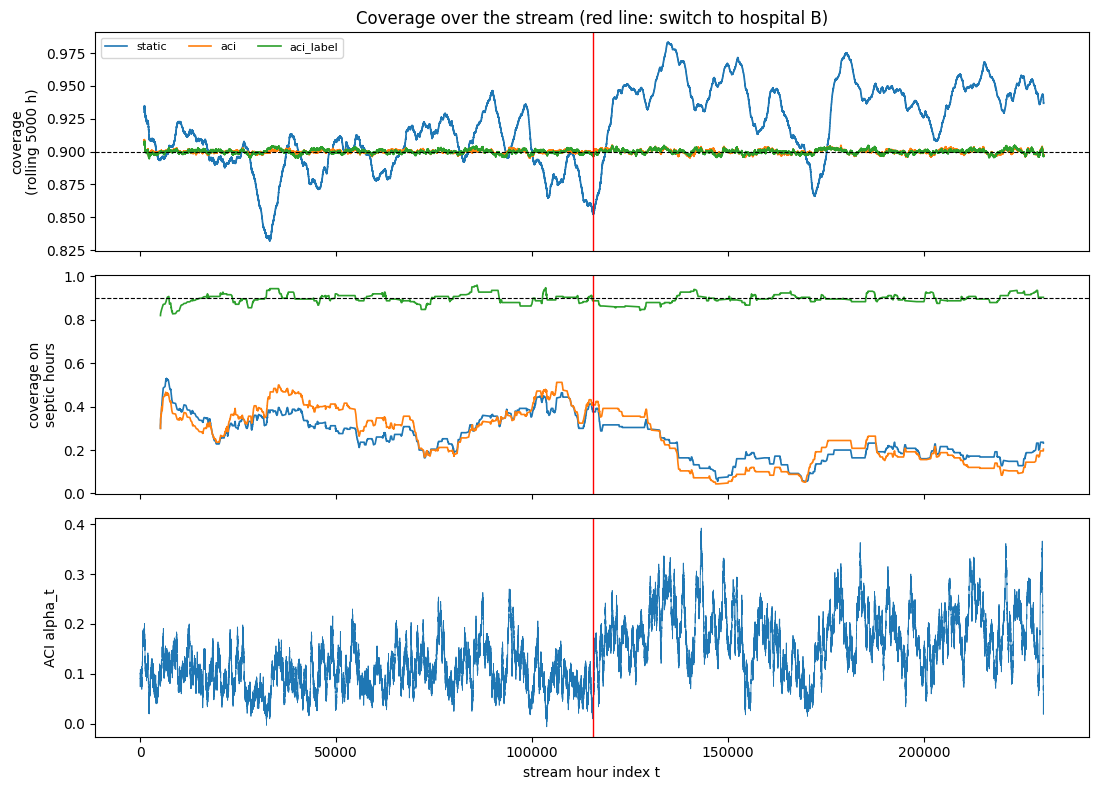

In [ ]:
# ============================================================
# 8c. COVERAGE OVER TIME (global, septic hours, and ACI's alpha_t)
# ============================================================
def rolling_mean(x, w):
    return pd.Series(np.asarray(x, dtype=float)).rolling(w, min_periods=max(10, w // 5)).mean().to_numpy()


W_ROLL = max(500, WINDOW_ROWS // 2)
pos = (stream["SepsisLabel"] == 1).to_numpy()
fig, axes = plt.subplots(3, 1, figsize=(11, 8), sharex=True)
for m in ["static", "aci", "aci_label"]:
    axes[0].plot(stream["t"], rolling_mean(stream[f"cov_{m}"], W_ROLL), label=m, lw=1.2)
    axes[1].plot(stream["t"][pos], rolling_mean(stream.loc[pos, f"cov_{m}"], max(50, W_ROLL // 20)), lw=1.2)
axes[2].plot(stream["t"], stream["alpha_aci"], lw=0.6)
for ax, lab in zip(axes, [f"coverage\n(rolling {W_ROLL} h)", "coverage on\nseptic hours", "ACI alpha_t"]):
    ax.axvline(CHANGE_T, color="red", lw=1)
    ax.set_ylabel(lab)
for ax in axes[:2]:
    ax.axhline(1 - ALPHA, ls="--", color="black", lw=0.8)
axes[0].legend(ncol=3, fontsize=8)
axes[0].set_title("Coverage over the stream (red line: switch to hospital B)")
axes[2].set_xlabel("stream hour index t")
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, "coverage_over_time.png"), dpi=150)
plt.show()

## 9. Conformalized EMM with patient-level inference
Two quality measures for a subgroup *S*:

* **coverage gap** `gap(S) = (1 − α) − Cov(S)` — validity; `> 0` means *S* is under-covered.
* **RAUL** `RAUL(S) = AUL(Ω) − AUL(S)`, where AUL is the average prediction-set size and Ω all hours of the data being mined — efficiency, as in Conformalized EMM (Du et al., 2025); computed from **static-threshold** set sizes so it reflects model uncertainty, not ACI's current state.

**Search** (`SEARCH` in Section 1). `"grid"`: the 14 descriptors and all their pairs (105 candidates, at most 2 conditions), all tested (Section 9b). `"beam"`: a beam search over raw variables with cut points from the data (Section 9c). A candidate needs `MIN_SUPPORT` of the rows **and** `MIN_PATIENTS` distinct patients. Uncertainty comes from a **patient-cluster bootstrap** (whole patients are resampled, so their correlated hours stay together); a subgroup is selected only if its standardised gap exceeds the family-wise **max-t** threshold over all candidates tested (Westfall–Young style), which accounts for testing many subgroups at once. The grid tests a family fixed in advance; the beam search chooses its candidates from the data, so they are tested on other patients (Section 9c).

In [ ]:
# ============================================================
# 9a. EMM MACHINERY
# ============================================================
def candidate_rules(descriptors=None):
    descriptors = descriptors or DESCRIPTORS
    return [(d,) for d in descriptors] + list(itertools.combinations(descriptors, 2))


def rule_name(rule):
    return " AND ".join(rule) if rule else "all"


def unique_rules(df, rules):
    """Drop rules that select no rows of df, and rules that select exactly the same rows as an earlier
    (shorter) rule - e.g. when a descriptor is true for every row, "X AND that descriptor" is just X."""
    M = rule_masks(df, rules)
    seen, keep = set(), []
    for j, rule in enumerate(rules):
        if not M[:, j].any():
            continue
        key = np.packbits(M[:, j]).tobytes()
        if key not in seen:
            seen.add(key)
            keep.append(rule)
    return keep


COND = globals().get("COND", {})   # beam-search conditions: name -> (variable, operator, value); see Section 9c


def descriptor_values(df, d):
    """Yes/no value of one condition for every row: a fixed descriptor column, or a beam-search condition such
    as 'HR > 104' computed from the carried-forward values (a missing value counts as 'no')."""
    if d in COND:
        var, op, v = COND[d]
        x = df[var].to_numpy(dtype=float)
        with np.errstate(invalid="ignore"):
            return x <= v if op == "<=" else (x > v if op == ">" else x == v)
    return df[d].to_numpy(dtype=bool)


def rule_masks(df, rules):
    """Boolean matrix (rows x rules): True where the row satisfies every condition of the rule."""
    cache, M = {}, np.ones((len(df), len(rules)), dtype=bool)
    for k, rule in enumerate(rules):
        for d in rule:
            if d not in cache:
                cache[d] = descriptor_values(df, d)
            M[:, k] &= cache[d]
    return M


def patient_sums(df, M, values):
    """Per-patient sums of `values` inside each rule (patients x rules) and overall (patients,)."""
    codes, uniq = pd.factorize(df["patient_id"])
    P = sparse.csr_matrix((np.asarray(values, dtype=float), (codes, np.arange(len(df)))),
                          shape=(len(uniq), len(df)))
    return np.asarray(P @ M.astype(float)), np.asarray(P.sum(axis=1)).ravel()


def score_rules(df, rules, cov_col, size_col, n_boot=N_BOOT, seed=SEED, alpha=ALPHA):
    """Coverage gap and RAUL of each rule plus patient-cluster bootstrap replicates."""
    M = rule_masks(df, rules)
    N, N_tot = patient_sums(df, M, np.ones(len(df)))
    E, _ = patient_sums(df, M, ~df[cov_col].to_numpy(dtype=bool))
    Z, Z_tot = patient_sums(df, M, df[size_col].to_numpy(dtype=float))

    def stats(w):
        with np.errstate(invalid="ignore", divide="ignore"):
            n = w @ N
            gap = (w @ E) / n - alpha                                   # = (1 - alpha) - coverage
            raul = np.asarray((w @ Z_tot) / (w @ N_tot))[..., None] - (w @ Z) / n
        return gap, raul

    P = N.shape[0]
    gap, raul = stats(np.ones(P))
    w_boot = np.random.default_rng(seed).multinomial(P, np.full(P, 1.0 / P), size=n_boot).astype(float)
    gap_b, raul_b = stats(w_boot)
    return dict(patients=(N > 0).sum(axis=0), rows=N.sum(axis=0), support=N.sum(axis=0) / len(df),
                coverage=1 - (gap + alpha), gap=gap, gap_b=gap_b, raul=raul, raul_b=raul_b, n_patients=P)


def emm_window(df, cov_col, size_col, rules=None, n_boot=N_BOOT, seed=SEED, fwer=FWER,
               min_support=MIN_SUPPORT, min_patients=MIN_PATIENTS, one_sided_gap=False):
    """Conformalized EMM on one window: score the candidates, keep those with enough rows AND patients,
    and flag those whose |gap| or |RAUL| exceeds the family-wise max-t threshold. one_sided_gap=True tests
    under-coverage only (gap > 0): for families of descriptions that were found as under-covered."""
    rules = unique_rules(df, rules or candidate_rules())
    r = score_rules(df, rules, cov_col, size_col, n_boot, seed)
    keep = (r["support"] >= min_support) & (r["patients"] >= min_patients)
    if not keep.any():
        return pd.DataFrame()
    stat = {}
    for key in ["gap", "raul"]:
        est, boot = r[key][keep], r[f"{key}_b"][:, keep]
        se = np.maximum(np.nanstd(boot, axis=0, ddof=1), 1e-6)
        z = (boot - est) / se
        if key == "gap" and one_sided_gap:
            crit = float(np.nanquantile(np.nanmax(z, axis=1), 1 - fwer))
            sig = est / se > crit
        else:
            crit = float(np.nanquantile(np.nanmax(np.abs(z), axis=1), 1 - fwer))
            sig = np.abs(est / se) > crit
        stat[key] = (est, se, est / se, sig, crit)
    kept = [x for x, k in zip(rules, keep) if k]
    res = pd.DataFrame({
        "subgroup": [rule_name(x) for x in kept], "rule": kept,
        "patients": r["patients"][keep], "rows": r["rows"][keep].astype(int), "support": r["support"][keep],
        "coverage": r["coverage"][keep],
        "coverage_gap": stat["gap"][0], "se_gap": stat["gap"][1], "t_gap": stat["gap"][2], "sig_gap": stat["gap"][3],
        "RAUL": stat["raul"][0], "se_RAUL": stat["raul"][1], "t_RAUL": stat["raul"][2], "sig_RAUL": stat["raul"][3],
    }).sort_values("coverage_gap", ascending=False).reset_index(drop=True)
    res.attrs.update(crit_gap=stat["gap"][4], crit_raul=stat["raul"][4], patients=r["n_patients"], rows=len(df))
    return res

In [ ]:
# ============================================================
# 9b. GRID SEARCH: STATIC CONFORMALIZED EMM ON THE CALIBRATION SET (hospital A), 14 clinical descriptors, depth 2
#     (reference subgroups from data independent of the stream, so later monitoring is not biased by selection)
# ============================================================
calib["cov_static"], calib["size_static"] = run_static(calib["p"].to_numpy(), y_cal, Q_marg(ALPHA), Q_marg(ALPHA))
emm_calib = emm_window(calib, "cov_static", "size_static")
print(f"calibration set: {emm_calib.attrs['patients']} patients | {len(emm_calib)} candidates pass the "
      f"support and patient filters | max-t critical value (coverage gap): {emm_calib.attrs['crit_gap']:.2f}")
SHOW = ["subgroup", "patients", "rows", "coverage", "coverage_gap", "t_gap", "sig_gap", "RAUL", "sig_RAUL"]
print("\nMost UNDER-covered subgroups:")
display(emm_calib.head(10)[SHOW].round(3))
print("\nSubgroups with the smallest sets (largest RAUL):")
display(emm_calib.sort_values("RAUL", ascending=False).head(5)[SHOW].round(3))


def label_breakdown(df, rule, cov_col):
    m = rule_masks(df, [rule])[:, 0]
    g = df.loc[m]
    septic = g["SepsisLabel"] == 1
    return pd.Series({"rows": len(g), "septic hours": int(septic.sum()),
                      "coverage on septic hours": g.loc[septic, cov_col].mean() if septic.any() else np.nan,
                      "coverage on other hours": g.loc[~septic, cov_col].mean()})


print("\nWhere does the under-coverage come from: missed septic hours or false alarms on other hours?")
display(pd.DataFrame({rule_name(r): label_breakdown(calib, r, "cov_static")
                      for r in emm_calib["rule"].head(5)}).T.round(3))
u = emm_calib[emm_calib["sig_gap"] & (emm_calib["coverage_gap"] > 0)]
print("significantly under-covered:", len(u), "| with positive RAUL:", int((u["RAUL"] > 0).sum()))
print("Pearson corr(gap, RAUL) over", len(emm_calib), "candidates:", round(emm_calib["coverage_gap"].corr(emm_calib["RAUL"]), 3))

calibration set: 3000 patients | 60 candidates pass the support and patient filters | max-t critical value (coverage gap): 3.40

Most UNDER-covered subgroups:


,subgroup,patients,rows,coverage,coverage_gap,t_gap,sig_gap,RAUL,sig_RAUL
0,unit_unknown AND temp_abnormal,784,8034,0.725,0.175,8.334,True,0.040,True
1,hr_gt_100 AND resp_gt_20,1229,10105,0.755,0.145,11.194,True,0.039,True
2,unit_unknown AND hr_gt_100,720,10305,0.768,0.132,8.438,True,0.039,True
3,male AND temp_abnormal,1026,9698,0.772,0.128,6.824,True,0.025,True
4,unit_micu AND hr_gt_100,460,6497,0.773,0.127,7.391,True,0.035,True
5,unit_unknown AND resp_gt_20,1225,18090,0.783,0.117,7.014,True,0.029,True
6,male AND hr_gt_100,891,11411,0.787,0.113,7.822,True,0.026,True
7,temp_abnormal,1743,15711,0.796,0.104,7.988,True,0.023,True
8,temp_abnormal AND wbc_abnormal,790,6053,0.796,0.104,5.707,True,0.026,True
9,early_stay_le_24h AND hr_gt_100,1338,11110,0.800,0.100,9.839,True,0.039,True



Subgroups with the smallest sets (largest RAUL):


,subgroup,patients,rows,coverage,coverage_gap,t_gap,sig_gap,RAUL,sig_RAUL
0,unit_unknown AND temp_abnormal,784,8034,0.725,0.175,8.334,True,0.040,True
2,unit_unknown AND hr_gt_100,720,10305,0.768,0.132,8.438,True,0.039,True
9,early_stay_le_24h AND hr_gt_100,1338,11110,0.800,0.100,9.839,True,0.039,True
1,hr_gt_100 AND resp_gt_20,1229,10105,0.755,0.145,11.194,True,0.039,True
4,unit_micu AND hr_gt_100,460,6497,0.773,0.127,7.391,True,0.035,True



Where does the under-coverage come from: missed septic hours or false alarms on other hours?


,rows,septic hours,coverage on septic hours,coverage on other hours
unit_unknown AND temp_abnormal,8034.0,395.0,0.413,0.741
hr_gt_100 AND resp_gt_20,10105.0,397.0,0.499,0.765
unit_unknown AND hr_gt_100,10305.0,426.0,0.479,0.781
male AND temp_abnormal,9698.0,410.0,0.422,0.787
unit_micu AND hr_gt_100,6497.0,307.0,0.332,0.795


significantly under-covered: 23 | with positive RAUL: 23
Pearson corr(gap, RAUL) over 60 candidates: 0.964


### 9c. Beam search with cut points from the data (`SEARCH = "beam"`)
The grid in 9b can only use our own 14 clinical cut-offs. Here EMM chooses the cut-offs itself from the data:

* **Conditions.** For every variable in `BEAM_VARS`: `x ≤ v` and `x > v` at the 10%, 20%, …, 90% quantiles over hours of its carried-forward values (about 18 conditions per variable), plus sex and ICU unit. A missing value counts as "no". With up to `BEAM_DEPTH` conditions per description there are millions of descriptions, too many to test one by one.
* **Beam search** (Duivesteijn et al. 2016, Algorithm 1). Level 1 scores every single condition. The best `BEAM_WIDTH` descriptions form the beam, and each next level adds one condition on a new variable to every description in the beam. Quality = coverage gap divided by its patient-clustered standard error (a *t*-value), so a big gap in a tiny group does not win. The beam keeps one description per *shape* (same variables and directions), so it does not fill up with copies that only differ in a cut-off.
* **Different results.** Going down the list from the best *t*, a description is kept only if it has a new shape and at most `MAX_OVERLAP` of its hours are already in descriptions kept before it (at most `TOP_K`). Without this, the list fills up with copies of the same patients.
* **Find on one half, test on the other.** The search uses the data to choose what to test, so a test on the same data would be far too optimistic. The calibration patients are split into two halves. The cut points and the search use the **discovery** half; the kept descriptions are then tested on the **validation** half with the patient bootstrap and a one-sided max-*t* (only under-coverage is claimed). That family is fixed before the test, so the test is honest. The confirmed ones become the EMM groups; the `N_EMM_GROUPS` most under-covered of them are passed on to monitoring and repair.
* For comparison, the grid search is run on the same two halves with the same filter for different results.

In [ ]:
# ============================================================
# 9c. EMM WITH BEAM SEARCH (SEARCH = "beam"): cut points from the data,
#     found on one half of the calibration patients, tested on the other half
# ============================================================
def make_conditions(df, variables, n_cuts):
    """'x <= v' and 'x > v' at the 10%, 20%, ..., 90% quantiles over the hours of each variable's carried-forward
    values in df (rounded to 3 significant digits; only cut points with values on both sides), plus 'female'."""
    conds = {}
    qs = np.linspace(0, 1, n_cuts + 2)[1:-1]
    for var in variables:
        if var not in df.columns:
            continue
        x = df[var].to_numpy(dtype=float)
        x = x[~np.isnan(x)]
        if len(x) == 0:
            continue
        for v in sorted({float(f"{q:.3g}") for q in np.quantile(x, qs)}):
            if x.min() <= v < x.max():
                conds[f"{var} <= {v:g}"] = (var, "<=", v)
                conds[f"{var} > {v:g}"] = (var, ">", v)
    conds["female"] = ("Gender", "==", 0.0)
    return conds


DESCRIPTOR_VAR = {"male": "Gender", "unit_micu": "Unit", "unit_sicu": "Unit", "unit_unknown": "Unit",
                  "age_gt_65": "Age", "early_stay_le_24h": "ICULOS", "hr_gt_100": "HR", "resp_gt_20": "Resp",
                  "temp_abnormal": "Temp", "sbp_lt_90": "SBP", "o2sat_lt_92": "O2Sat", "wbc_abnormal": "WBC",
                  "lactate_gt_2": "Lactate", "creatinine_gt_1_2": "Creatinine"}


def cond_var(d):
    """The variable a condition is about; a description never uses the same variable twice."""
    if d in COND:
        return COND[d][0]
    return DESCRIPTOR_VAR.get(d, d)


def cond_shape(rule):
    """Variables and directions of a description, e.g. {(HR, >), (Resp, >)}: descriptions with the same shape only
    differ in their cut-offs."""
    return frozenset((cond_var(d), COND[d][1] if d in COND else d) for d in rule)


def pick_diverse(df, rules, top_k=TOP_K, max_overlap=MAX_OVERLAP, mask_fn=None):
    """Go down a list of descriptions (best first) and keep one only if it has a new shape and at most max_overlap
    of its hours are already in descriptions kept before it."""
    mask_fn = mask_fn or (lambda rule: rule_masks(df, [rule])[:, 0])
    kept, covered, shapes = [], np.zeros(len(df), dtype=bool), set()
    for rule in rules:
        if len(kept) >= top_k:
            break
        sh = cond_shape(rule)
        if sh in shapes:
            continue
        m = mask_fn(rule)
        if np.count_nonzero(m & covered) > max_overlap * np.count_nonzero(m):
            continue
        kept.append(rule)
        covered |= m
        shapes.add(sh)
    return kept


def search_space_size(conditions, depth):
    """Number of descriptions with 1 to `depth` conditions on different variables."""
    e = [1] + [0] * depth                                   # elementary symmetric sums of the counts per variable
    for c in pd.Series([cond_var(d) for d in conditions]).value_counts().to_numpy():
        for k in range(depth, 0, -1):
            e[k] += e[k - 1] * int(c)
    return sum(e[1:])


def beam_search(df, cov_col, conditions, width=BEAM_WIDTH, depth=BEAM_DEPTH, top_k=TOP_K,
                min_support=MIN_SUPPORT, min_patients=MIN_PATIENTS, max_overlap=MAX_OVERLAP, alpha=ALPHA):
    """Beam search for under-covered subgroups. Quality = coverage gap / patient-clustered standard error.
    Returns up to top_k descriptions over all levels (best t first; each with a new shape and at most max_overlap of
    its hours inside descriptions kept before it) and the number of descriptions evaluated."""
    codes, uniq = pd.factorize(df["patient_id"])
    n_rows, P = len(df), len(uniq)
    miss = (~df[cov_col].to_numpy(dtype=bool)).astype(np.float32)
    A = sparse.csr_matrix((np.ones(n_rows, np.float32), (codes, np.arange(n_rows))), shape=(P, n_rows))
    Am = sparse.csr_matrix((miss, (codes, np.arange(n_rows))), shape=(P, n_rows))
    col = {d: descriptor_values(df, d) for d in conditions}
    var = {d: cond_var(d) for d in conditions}

    def mask(rule):
        m = col[rule[0]].copy()
        for d in rule[1:]:
            m &= col[d]
        return m

    def evaluate(rules):
        out = []
        for s in range(0, len(rules), 128):
            chunk = rules[s:s + 128]
            M = np.column_stack([mask(r) for r in chunk]).astype(np.float32)
            N, E = np.asarray(A @ M, dtype=float), np.asarray(Am @ M, dtype=float)   # patients x rules
            n, e, G = N.sum(axis=0), E.sum(axis=0), (N > 0).sum(axis=0)
            with np.errstate(invalid="ignore", divide="ignore"):
                r = e / n                                                  # share of missed hours
                se = np.sqrt(G / (G - 1) * ((E - r * N) ** 2).sum(axis=0)) / n   # clustered by patient
                t = np.where(se > 0, (r - alpha) / se, np.where(r > alpha, np.inf, -np.inf))
            for j, rule in enumerate(chunk):
                if n[j] >= min_support * n_rows and G[j] >= min_patients and not np.isnan(t[j]):
                    out.append({"rule": rule, "depth": len(rule), "patients": int(G[j]), "rows": int(n[j]),
                                "support": n[j] / n_rows, "coverage": 1 - r[j], "coverage_gap": r[j] - alpha,
                                "t": t[j]})
        return out

    seen, found, level, n_eval = set(), [], [(d,) for d in conditions], 0
    for lev in range(1, depth + 1):
        cand = []
        for rule in level:
            if frozenset(rule) not in seen:
                seen.add(frozenset(rule))
                cand.append(rule)
        n_eval += len(cand)
        res = sorted(evaluate(cand), key=lambda x: -x["t"])
        found += res
        if lev == depth or not res:
            break
        beam, shapes = [], set()
        for x in res:                                       # the best description of each shape
            if len(beam) >= width:
                break
            sh = cond_shape(x["rule"])
            if sh not in shapes:
                shapes.add(sh)
                beam.append(x["rule"])
        level = [b + (d,) for b in beam for d in conditions if var[d] not in {var[c] for c in b}]
    found.sort(key=lambda x: -x["t"])
    by_rule = {x["rule"]: x for x in found if x["t"] > 0}
    kept = pick_diverse(df, list(by_rule), top_k, max_overlap, mask_fn=mask)
    return [by_rule[r] for r in kept], n_eval


def grid_groups(label):
    # with SEARCH = "grid" (or as a fallback): the most under-covered significant subgroups of the grid search on
    # the calibration set (9b)
    significant_under = emm_calib[emm_calib["sig_gap"] & (emm_calib["coverage_gap"] > 0)]
    groups = list(significant_under["rule"].head(N_EMM_GROUPS))
    if not groups:
        print("\nNo significantly under-covered subgroup on the calibration set -> using the top candidates "
              "by coverage gap (NOT significant) for monitoring and repair.")
        return list(emm_calib["rule"].head(N_EMM_GROUPS)), label + ", NOT significant"
    return groups, label


beam_disc, beam_val, search_compare = pd.DataFrame(), pd.DataFrame(), pd.DataFrame()
if SEARCH == "beam":
    t0 = time.time()
    cal_ids = calib["patient_id"].unique()
    disc_ids = set(np.random.default_rng(SEED + 99).permutation(cal_ids)[: len(cal_ids) // 2])
    in_disc = calib["patient_id"].isin(disc_ids).to_numpy()
    calib_disc, calib_val = calib[in_disc], calib[~in_disc]
    COND.clear()
    COND.update(make_conditions(calib_disc, BEAM_VARS, N_CUTS))      # cut points from the discovery half only
    BEAM_CONDITIONS = list(COND) + ["male", "unit_micu", "unit_sicu", "unit_unknown"]
    found, n_eval = beam_search(calib_disc, "cov_static", BEAM_CONDITIONS)
    print(f"{len(BEAM_CONDITIONS)} conditions on {len({cond_var(d) for d in BEAM_CONDITIONS})} variables: "
          f"{search_space_size(BEAM_CONDITIONS, BEAM_DEPTH):,} possible descriptions with up to {BEAM_DEPTH} "
          f"conditions; the beam search evaluated {n_eval:,} of them ({time.time() - t0:.0f}s)")
    beam_disc = pd.DataFrame(found)
    if len(beam_disc):
        beam_disc.insert(0, "subgroup", [rule_name(r) for r in beam_disc["rule"]])
        print(f"\nDiscovery half ({calib_disc['patient_id'].nunique()} patients): the {len(beam_disc)} most "
              "under-covered descriptions found (different shapes, mostly new hours)")
        display(beam_disc.drop(columns="rule").round(3))
        beam_val = emm_window(calib_val, "cov_static", "size_static", rules=list(beam_disc["rule"]),
                              seed=SEED + 1, one_sided_gap=True)
    if len(beam_val):
        print(f"\nValidation half ({calib_val['patient_id'].nunique()} patients): {len(beam_val)} of these descriptions "
              f"have enough patients there; tested with the patient bootstrap and one-sided max-t (critical value "
              f"{beam_val.attrs['crit_gap']:.2f})")
        display(beam_val[SHOW].round(3))

    # the grid search on the same two halves, with the same filter for different results
    grid_disc = emm_window(calib_disc, "cov_static", "size_static", seed=SEED + 2)
    grid_sel = grid_disc[grid_disc["coverage_gap"] > 0] if len(grid_disc) else grid_disc
    grid_top = (pick_diverse(calib_disc, list(grid_sel.sort_values("t_gap", ascending=False)["rule"]))
                if len(grid_sel) else [])
    grid_val = (emm_window(calib_val, "cov_static", "size_static", rules=grid_top, seed=SEED + 3,
                           one_sided_gap=True) if grid_top else pd.DataFrame())

    def search_summary(name, v):
        c = v[v["sig_gap"] & (v["coverage_gap"] > 0)] if len(v) else v
        low = c["coverage"].nsmallest(N_EMM_GROUPS) if len(c) else pd.Series(dtype=float)
        return {"search": name, "tested on the validation half": len(v), "confirmed under-covered": len(c),
                "mean coverage (all tested)": v["coverage"].mean() if len(v) else np.nan,
                "lowest coverage (confirmed)": low.min() if len(low) else np.nan,
                f"mean coverage of the {N_EMM_GROUPS} lowest confirmed (or fewer)": low.mean() if len(low) else np.nan}

    search_compare = pd.DataFrame([search_summary("grid: 14 clinical conditions, up to 2", grid_val),
                                   search_summary(f"beam: cut points from the data, up to {BEAM_DEPTH}", beam_val)])
    print("\nGrid versus beam search (both found on the discovery half with the same filter for different "
          "results, tested on the validation half):")
    display(search_compare.round(3))

    conf = beam_val[beam_val["sig_gap"] & (beam_val["coverage_gap"] > 0)] if len(beam_val) else beam_val
    EMM_GROUPS = list(conf["rule"].head(N_EMM_GROUPS)) if len(conf) else []
    EMM_SOURCE = "beam, confirmed on the validation half"
    if not EMM_GROUPS and len(beam_disc):
        print("\nNo discovered subgroup was confirmed on the validation half -> using the best ones found "
              "(NOT confirmed) for monitoring and repair.")
        EMM_GROUPS = list(beam_disc["rule"].head(N_EMM_GROUPS))
        EMM_SOURCE = "beam, NOT confirmed"
    if not EMM_GROUPS:
        print("\nThe beam search returned no description -> using the grid subgroups of Section 9b.")
        EMM_GROUPS, EMM_SOURCE = grid_groups("grid (fallback)")
else:
    EMM_GROUPS, EMM_SOURCE = grid_groups("grid (Section 9b)")
PREDEFINED_GROUPS = [(d,) for d in DESCRIPTORS]
MONITORED = list(dict.fromkeys(EMM_GROUPS + PREDEFINED_GROUPS))
print(f"\nEMM reference subgroups ({EMM_SOURCE}):", [rule_name(r) for r in EMM_GROUPS])


EMM reference subgroups (grid (Section 9b)): ['unit_unknown AND temp_abnormal', 'hr_gt_100 AND resp_gt_20', 'unit_unknown AND hr_gt_100', 'male AND temp_abnormal', 'unit_micu AND hr_gt_100', 'unit_unknown AND resp_gt_20', 'male AND hr_gt_100', 'temp_abnormal']


## 10. Monitoring subgroup coverage — at the patient level
Monitors receive information **per finished stay**, never per hour: hours within a patient are strongly correlated, so treating them as independent evidence (as hourly ADWIN does) produces false alarms.

* **Main monitor:** one-sided CUSUM per subgroup on the *excess missed hours* of each finished stay, `(μ0 − δ/2)·hours − covered hours`, standardised by its burn-in spread (`CUSUM_WEIGHTING = "patient"` gives each stay one vote instead). Validity does **not** rely on hours being independent: one **joint threshold** for all subgroups is calibrated by resampling whole burn-in patients, so the chance of *any* false alarm before the change is about `CUSUM_FA`.
* **Baselines:** ADWIN on hourly coverage and ADWIN on one value per stay, both with `clock=1` and restarted after each signal.

Delays are in **ICU clock hours after the switch**, so all monitors share one scale. A delay is only meaningful for subgroups whose coverage really dropped (`drop` column); an alarm after the switch on a stable subgroup is a false alarm that happened late.

In [ ]:
# ============================================================
# 10a. MONITORING TOOLS
# ============================================================
MON_METHOD = "aci"     # monitor the coverage that the deployed method actually delivered


def patient_counts(st, rules, cov_col):
    # Per finished stay and subgroup: covered hours C and hours N, ordered by the stay's last hour in the stream.
    M = rule_masks(st, rules)
    N, _ = patient_sums(st, M, np.ones(len(st)))
    C, _ = patient_sums(st, M, st[cov_col].to_numpy(dtype=float))
    codes, uniq = pd.factorize(st["patient_id"])
    info = pd.DataFrame({"code": codes, "t": st["t"].to_numpy(), "hospital": st["hospital"].to_numpy()}
                        ).groupby("code").agg(t_last=("t", "max"), hospital=("hospital", "first"))
    order = np.argsort(info["t_last"].to_numpy(), kind="stable")
    return (C[order], N[order], np.asarray(uniq)[order],
            info["t_last"].to_numpy()[order], info["hospital"].to_numpy()[order])


def cusum_increments(C, N, mu0, drop=CUSUM_DROP, weighting=CUSUM_WEIGHTING):
    # Positive when a stay has more missed hours than expected after a drop of drop/2; NaN if not in the subgroup.
    with np.errstate(invalid="ignore", divide="ignore"):
        inc = (mu0 - drop / 2) * N - C if weighting == "hours" else (mu0 - drop / 2) - C / N
    return np.where(N > 0, inc, np.nan)


def cusum_threshold(C_ref, N_ref, mu0, scale, horizon, fa, n_boot, seed):
    # Joint threshold for all subgroups: resample whole burn-in stays so that
    # P(any alarm on any subgroup within `horizon` stays) is about `fa`.
    rng = np.random.default_rng(seed)
    S, S_max = np.zeros((n_boot, C_ref.shape[1])), np.zeros(n_boot)
    for _ in range(horizon):
        idx = rng.integers(0, len(C_ref), size=n_boot)
        inc = cusum_increments(C_ref[idx], N_ref[idx], mu0) / scale
        S = np.where(np.isnan(inc), S, np.maximum(0.0, S + np.nan_to_num(inc)))
        S_max = np.maximum(S_max, S.max(axis=1))
    return float(np.quantile(S_max, 1 - fa))


def cusum_alarms(C_seq, N_seq, mu0, scale, h):
    # One-sided CUSUM per subgroup, restarted after each alarm. Returns (position, subgroup index) pairs.
    inc_all = cusum_increments(C_seq, N_seq, mu0) / scale
    S, alarms = np.zeros(C_seq.shape[1]), []
    for i, inc in enumerate(inc_all):
        ok = ~np.isnan(inc)
        S[ok] = np.maximum(0.0, S[ok] + inc[ok])
        for k in np.where(S > h)[0]:
            alarms.append((i, int(k)))
            S[k] = 0.0
    return alarms


class FallbackADWIN:
    """Re-implementation of river's ADWIN cut rule (Bernstein bound, exponential-histogram cut points).
    Used only when river is not installed; install river for the reported results."""

    def __init__(self, delta=0.002, clock=1, min_window_length=5, grace_period=10):
        self.delta, self.clock, self.min_len, self.grace = delta, clock, min_window_length, grace_period
        self.cs, self.cq, self.tick, self.drift_detected = [0.0], [0.0], 0, False

    @staticmethod
    def _cuts(n):
        cuts, size, total = [], 1, 0
        while True:
            for _ in range(5):
                total += size
                if total >= n:
                    return cuts
                cuts.append(total)
            size *= 2

    def update(self, x):
        self.cs.append(self.cs[-1] + x)
        self.cq.append(self.cq[-1] + x * x)
        self.tick += 1
        self.drift_detected = False
        n = len(self.cs) - 1
        if n <= self.grace or self.tick % self.clock:
            return
        S, var = self.cs[-1], self.cq[-1] / n - (self.cs[-1] / n) ** 2
        dd = math.log(2 * math.log(n) / self.delta)
        for n1 in self._cuts(n):
            n0 = n - n1
            if n0 <= self.min_len or n1 <= self.min_len:
                continue
            u1 = S - self.cs[n - n1]
            m = 1.0 / (n0 - self.min_len + 1) + 1.0 / (n1 - self.min_len + 1)
            if abs((S - u1) / n0 - u1 / n1) > math.sqrt(2 * m * var * dd) + 2.0 / 3.0 * dd * m:
                self.drift_detected = True
                return


def make_adwin():
    if _RiverADWIN is None:
        return FallbackADWIN(delta=0.002, clock=1)
    try:
        return _RiverADWIN(delta=0.002, clock=1)
    except TypeError:                                   # very old river versions have no `clock`
        return _RiverADWIN(delta=0.002)


def adwin_alarms(values):
    # Positions where ADWIN signals a change; the detector is restarted after every signal.
    det, alarms = make_adwin(), []
    for i, v in enumerate(values):
        det.update(float(v))
        if det.drift_detected:
            alarms.append(i)
            det = make_adwin()
    return np.asarray(alarms, dtype=int)

In [ ]:
# ============================================================
# 10b. RUN THE MONITORS
# ============================================================
cov_col = f"cov_{MON_METHOD}"
C_pat, N_pat, pat_ids, pat_tlast, pat_hosp = patient_counts(stream, MONITORED, cov_col)
change_pos = int(np.argmax(pat_hosp == "B"))                       # first hospital-B stay (discharge order)
burn_end = int(BURN_IN_FRAC * (pat_hosp == "A").sum())
assert 0 < burn_end < change_pos, "burn-in must end before the change point; lower BURN_IN_FRAC"

ref_C, ref_N = C_pat[:burn_end], N_pat[:burn_end]
n_ref = (ref_N > 0).sum(axis=0)
with np.errstate(invalid="ignore", divide="ignore"), warnings.catch_warnings():
    warnings.simplefilter("ignore", RuntimeWarning)               # subgroups with < 2 burn-in stays -> NaN
    mu0 = ref_C.sum(axis=0) / ref_N.sum(axis=0)                    # hour-weighted baseline coverage
    scale = np.nanstd(cusum_increments(ref_C, ref_N, mu0), axis=0, ddof=1)
usable = (n_ref >= 30) & np.isfinite(scale) & (scale > 0)
mon_rules = [r for r, u in zip(MONITORED, usable) if u]
C_u, N_u, mu0_u, scale_u = C_pat[:, usable], N_pat[:, usable], mu0[usable], scale[usable]

h = cusum_threshold(C_u[:burn_end], N_u[:burn_end], mu0_u, scale_u, change_pos - burn_end, CUSUM_FA, N_BOOT, SEED)
alarm_pos = [(burn_end + i, k) for i, k in cusum_alarms(C_u[burn_end:], N_u[burn_end:], mu0_u, scale_u, h)]

clock = stream["clock"].to_numpy()
t_arr = stream["t"].to_numpy()
cov_arr = stream[cov_col].to_numpy(dtype=float)
CHANGE_CLOCK = clock[CHANGE_T]
monitor_start_t = int(pat_tlast[burn_end - 1]) + 1
M_rows = rule_masks(stream, mon_rules)


def first_delay(alarm_clock):
    after = np.asarray(alarm_clock)[np.asarray(alarm_clock) >= CHANGE_CLOCK]
    return float(after[0] - CHANGE_CLOCK) if len(after) else np.nan


mon_records = []
for k, rule in enumerate(mon_rules):
    cus = np.array([p for p, kk in alarm_pos if kk == k], dtype=int)
    sel = M_rows[:, k] & (t_arr >= monitor_start_t)
    hourly_clock = clock[t_arr[sel][adwin_alarms(cov_arr[sel])]] if sel.any() else np.array([])
    with np.errstate(invalid="ignore", divide="ignore"):
        frac = C_u[burn_end:, k] / N_u[burn_end:, k]
    ok = ~np.isnan(frac)
    pat_alarm = np.arange(burn_end, len(C_u))[ok][adwin_alarms(frac[ok])] if ok.any() else np.array([], int)
    after_C, after_N = C_u[change_pos:, k].sum(), N_u[change_pos:, k].sum()
    cov_after = after_C / after_N if after_N > 0 else np.nan
    mon_records.append({
        "subgroup": rule_name(rule), "source": "EMM" if rule in EMM_GROUPS else "predefined",
        "baseline stays": int(n_ref[usable][k]), "stays after change": int((N_u[change_pos:, k] > 0).sum()),
        "coverage baseline": mu0_u[k], "coverage after change": cov_after, "drop": mu0_u[k] - cov_after,
        "CUSUM false alarms": int(np.sum(cus < change_pos)),
        "CUSUM delay (h)": first_delay(clock[pat_tlast[cus]]) if len(cus) else np.nan,
        "hourly-ADWIN false alarms": int(np.sum(hourly_clock < CHANGE_CLOCK)),
        "hourly-ADWIN delay (h)": first_delay(hourly_clock),
        "patient-ADWIN false alarms": int(np.sum(pat_alarm < change_pos)),
        "patient-ADWIN delay (h)": first_delay(clock[pat_tlast[pat_alarm]]) if len(pat_alarm) else np.nan,
    })
mon_df = pd.DataFrame(mon_records).sort_values("drop", ascending=False).reset_index(drop=True)
print(f"burn-in: {burn_end} stays | monitored before the change: {change_pos - burn_end} | after: "
      f"{len(C_u) - change_pos} | {len(mon_rules)} subgroups | joint CUSUM threshold h = {h:.2f} "
      f"({CUSUM_WEIGHTING}-weighted, tuned for a {CUSUM_DROP:.2f} drop)")
display(mon_df.round(3))
print("False alarms before the change, summed over subgroups:",
      {c.replace(" false alarms", ""): int(mon_df[c].sum()) for c in mon_df.columns if "false alarms" in c})

burn-in: 900 stays | monitored before the change: 2073 | after: 3027 | 21 subgroups | joint CUSUM threshold h = 59.25 (hours-weighted, tuned for a 0.05 drop)


,subgroup,source,baseline stays,stays after change,coverage baseline,coverage after change,drop,CUSUM false alarms,CUSUM delay (h),hourly-ADWIN false alarms,hourly-ADWIN delay (h),patient-ADWIN false alarms,patient-ADWIN delay (h)
0,sbp_lt_90,predefined,314,888,0.875,0.780,0.095,0,752.250,3,609.250,0,NaN
1,unit_sicu,predefined,260,1022,0.982,0.915,0.068,0,548.110,10,163.794,0,NaN
2,o2sat_lt_92,predefined,256,988,0.902,0.844,0.058,1,950.329,2,850.975,0,NaN
3,lactate_gt_2,predefined,163,362,0.908,0.850,0.057,0,2035.167,11,217.396,0,NaN
4,male AND hr_gt_100,EMM,270,736,0.820,0.779,0.042,0,NaN,3,626.503,0,NaN
5,creatinine_gt_1_2,predefined,271,976,0.899,0.870,0.029,0,NaN,10,93.671,0,NaN
6,resp_gt_20,predefined,792,2426,0.857,0.828,0.029,0,NaN,2,646.250,0,NaN
7,unit_micu AND hr_gt_100,EMM,130,537,0.778,0.752,0.026,0,NaN,4,11.800,0,NaN
8,hr_gt_100 AND resp_gt_20,EMM,362,981,0.764,0.738,0.026,0,NaN,2,113.905,0,NaN
9,hr_gt_100,predefined,478,1427,0.814,0.796,0.018,0,NaN,4,144.070,0,NaN


False alarms before the change, summed over subgroups: {'CUSUM': 1, 'hourly-ADWIN': 104, 'patient-ADWIN': 0}


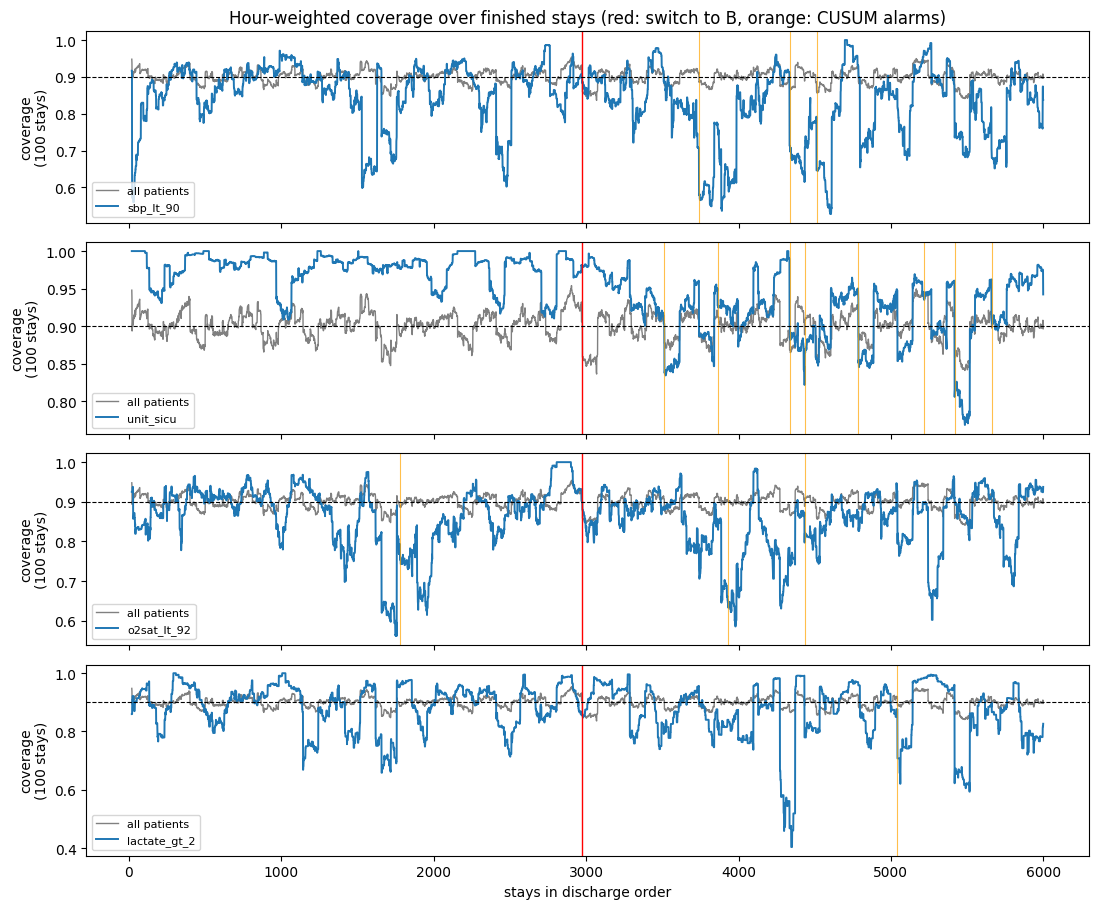

In [ ]:
# ============================================================
# 10c. PLOT: global coverage vs the subgroups whose coverage dropped most
# ============================================================
def rolling_coverage(C, N, w=100):
    return (pd.Series(C).rolling(w, min_periods=20).sum() / pd.Series(N).rolling(w, min_periods=20).sum()).to_numpy()


C_all, N_all, _, _, _ = patient_counts(stream, [()], cov_col)        # empty rule = all hours of each stay
glob_roll = rolling_coverage(C_all[:, 0], N_all[:, 0])
top = mon_df.head(4)
fig, axes = plt.subplots(len(top), 1, figsize=(11, 2.3 * len(top)), sharex=True, squeeze=False)
for ax, (_, row) in zip(axes[:, 0], top.iterrows()):
    k = mon_rules.index(tuple(row["subgroup"].split(" AND ")))
    ax.plot(glob_roll, color="grey", lw=1, label="all patients")
    ax.plot(rolling_coverage(C_u[:, k], N_u[:, k]), lw=1.4, label=row["subgroup"])
    for p, kk in alarm_pos:
        if kk == k:
            ax.axvline(p, color="orange", lw=0.8, alpha=0.7)
    ax.axvline(change_pos, color="red", lw=1)
    ax.axhline(1 - ALPHA, ls="--", color="black", lw=0.8)
    ax.set_ylabel("coverage\n(100 stays)")
    ax.legend(fontsize=8, loc="lower left")
axes[0, 0].set_title("Hour-weighted coverage over finished stays (red: switch to B, orange: CUSUM alarms)")
axes[-1, 0].set_xlabel("stays in discharge order")
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, "subgroup_monitoring.png"), dpi=150)
plt.show()

## 11. Re-mining: mine on window *k*, validate on window *k + 1* — for every window
Every window is mined exactly once (no duplicated pairs). A subgroup is selected in window *k* if it is significantly under-covered (max-t), then checked on the next window: it **persists** if its 95% patient-bootstrap interval for the gap is still above 0. Two comparisons make the result interpretable:

* persistence in windows **with** vs **without** a CUSUM alarm, and before vs after the change;
* a **random patient-matched null**: how often a random set of the same number of patients looks at least as under-covered in window *k + 1*.

Window *k + 1* is checked **only on patients who were not in window *k*** (stays can cross the border between windows), so the check uses new patients. With `SEARCH = "beam"`, the search chooses what to test, so in window *k* it runs on one half of the window's patients and the max-*t* test (one-sided: under-coverage only) on the other half. The window-*k* columns then describe that test half, so selected-pair counts and persistence rates cannot be compared directly between the two search modes.

In [ ]:
# ============================================================
# 11. MINE -> VALIDATE ON EVERY WINDOW
# ============================================================
stream["window"] = stream["t"] // WINDOW_ROWS
alarm_windows = {int(pat_tlast[p] // WINDOW_ROWS) for p, _ in alarm_pos}
rng_null = np.random.default_rng(SEED + 7)
records, n_mined = [], 0
windows = sorted(stream["window"].unique())
for k in windows[:-1]:
    wk, wk1 = stream[stream["window"] == k], stream[stream["window"] == k + 1]
    wk1 = wk1[~wk1["patient_id"].isin(wk["patient_id"].unique())]          # check on new patients only
    if min(wk["patient_id"].nunique(), wk1["patient_id"].nunique()) < 2 * MIN_PATIENTS:
        continue
    n_mined += 1
    if SEARCH == "beam":
        # find on one half of the window's patients, test on the other half (the search chooses what to test)
        ids_k = wk["patient_id"].unique()
        half = set(np.random.default_rng(SEED + 20_000 + int(k)).permutation(ids_k)[: len(ids_k) // 2])
        in_half = wk["patient_id"].isin(half).to_numpy()
        found_k, _ = beam_search(wk[in_half], cov_col, BEAM_CONDITIONS)
        mined = (emm_window(wk[~in_half], cov_col, "size_static", rules=[x["rule"] for x in found_k],
                            seed=SEED + int(k), one_sided_gap=True) if found_k else pd.DataFrame())
    else:
        mined = emm_window(wk, cov_col, "size_static", seed=SEED + int(k))
    if mined.empty:
        continue
    sel = mined[mined["sig_gap"] & (mined["coverage_gap"] > 0)]
    if sel.empty:
        continue
    val = score_rules(wk1, list(sel["rule"]), cov_col, "size_static", seed=SEED + 10_000 + int(k))
    se1 = np.nanstd(val["gap_b"], axis=0, ddof=1)
    per_pat = wk1.groupby("patient_id")[cov_col].agg(["sum", "size"])
    covered_p, hours_p = per_pat["sum"].to_numpy(float), per_pat["size"].to_numpy(float)
    share_B = (wk["hospital"] == "B").mean()
    for j, (_, row) in enumerate(sel.iterrows()):
        n_p, gap1 = int(val["patients"][j]), float(val["gap"][j])
        if 2 <= n_p <= len(covered_p) and not np.isnan(gap1):
            draws = [1 - covered_p[i].sum() / hours_p[i].sum() - ALPHA
                     for i in (rng_null.choice(len(covered_p), n_p, replace=False) for _ in range(200))]
            p_null = (1 + np.sum(np.asarray(draws) >= gap1)) / 201
        else:
            p_null = np.nan
        records.append({
            "window": int(k), "segment": "A" if share_B == 0 else ("B" if share_B == 1 else "A->B"),
            "alarm in window": int(k) in alarm_windows, "subgroup": row["subgroup"],
            "patients k": int(row["patients"]), "gap k": row["coverage_gap"],
            "patients k+1": n_p, "gap k+1": gap1,
            "ci low k+1": gap1 - 1.96 * se1[j], "ci high k+1": gap1 + 1.96 * se1[j],
            "persists": bool(n_p >= MIN_PATIENTS and gap1 - 1.96 * se1[j] > 0),
            "null p (random patients)": p_null,
        })
win_df = pd.DataFrame(records)
print(f"{n_mined} windows mined; {len(win_df)} (window, subgroup) pairs selected")
if not win_df.empty:
    display(win_df.groupby("segment")["persists"].agg(["mean", "size"]).round(3))
    display(win_df.groupby("alarm in window")["persists"].agg(["mean", "size"]).round(3))
    display(win_df.sort_values("gap k+1", ascending=False).head(15).round(3))

22 windows mined; 41 (window, subgroup) pairs selected


,mean,size
segment,,
A,0.769,26
B,0.667,15


,mean,size
alarm in window,,
False,0.727,22
True,0.737,19


,window,segment,alarm in window,subgroup,patients k,gap k,patients k+1,gap k+1,ci low k+1,ci high k+1,persists,null p (random patients)
38,21,B,True,hr_gt_100 AND resp_gt_20,97,0.148,95,0.187,0.105,0.269,True,0.005
12,7,A,False,resp_gt_20 AND temp_abnormal,105,0.159,75,0.178,0.044,0.312,True,0.005
14,7,A,False,hr_gt_100 AND resp_gt_20,112,0.139,101,0.175,0.087,0.263,True,0.005
33,18,B,True,hr_gt_100 AND resp_gt_20,101,0.254,83,0.174,0.069,0.278,True,0.005
28,14,B,True,unit_micu AND hr_gt_100,47,0.272,43,0.151,0.047,0.256,True,0.005
0,0,A,False,unit_unknown AND temp_abnormal,75,0.233,59,0.149,0.063,0.236,True,0.005
9,6,A,True,unit_unknown AND resp_gt_20,126,0.137,101,0.147,0.079,0.215,True,0.005
39,21,B,True,early_stay_le_24h AND hr_gt_100,109,0.145,117,0.146,0.077,0.214,True,0.005
1,4,A,False,resp_gt_20 AND temp_abnormal,104,0.228,79,0.139,0.008,0.271,True,0.005
36,19,B,True,hr_gt_100 AND resp_gt_20,92,0.175,66,0.138,0.037,0.239,True,0.005


## 12. Repair prototype: group-conditional online conformal
Threshold `τ_t(x, y) = θ · c(x, y)` with `c = [1, 1{y = 1}, group indicators]`. After the label arrives: `θ ← θ + η (err_t − α) c(X_t, Y_t)` — an online gradient step on the pinball loss (the idea behind GCACI, Ramalingam et al. 2025; this is a simple re-implementation, not their code). Compared on hospital B:

* `gc_predefined` — groups = the single clinical descriptors;
* `gc_emm` — groups = the EMM subgroups found on the **calibration set** (before the shift).

Evaluation uses **all** candidate subgroups with enough patients in B, including ones neither method was given. These clinical-descriptor subgroups (those of the 105 grid descriptions with enough patients and hours in B) favour the predefined groups, because that repair was given exactly these conditions. With `SEARCH = "beam"` an **audit** is added: for each method, a beam search on half of the patients after the change looks for the subgroups where that method is most clearly under-covered (highest *t*), using both the data-driven conditions and the 14 clinical conditions; their coverage is then measured on the other half. No method was given these subgroups, so the audit favours neither list. It reports the number of subgroups found, their mean coverage and the worst one.

Hospital-B segment: 91 clinical-descriptor subgroups with >= 20 patients and 1% of the hours


,method,coverage,coverage on septic hours,mean set size,worst subgroup coverage,subgroups below 0.85,mean shortfall
0,static,0.941,0.182,0.983,0.735,19,0.024
1,static_label,0.941,0.688,1.411,0.754,16,0.020
2,aci,0.900,0.157,0.933,0.654,45,0.061
3,aci_label,0.900,0.902,1.632,0.689,42,0.053
4,gc_predefined,0.900,0.895,1.550,0.860,0,0.005
5,gc_emm,0.900,0.894,1.577,0.746,21,0.030


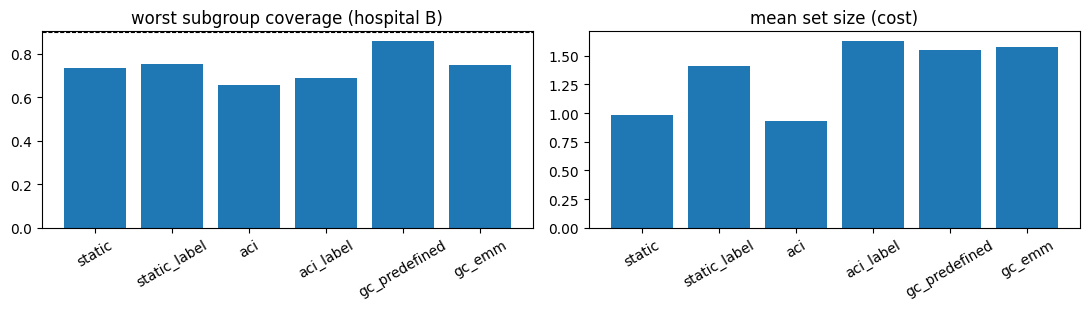

In [ ]:
# ============================================================
# 12. REPAIR PROTOTYPE
# ============================================================
def run_group_conditional(st, groups, eta=GC_ETA, alpha=ALPHA):
    p, y = st["p"].to_numpy(), st["SepsisLabel"].to_numpy().astype(int)
    G = rule_masks(st, groups).astype(float) if groups else np.zeros((len(st), 0))
    q0, q1 = np.clip(Q_cls[0](alpha), 0, 1), np.clip(Q_cls[1](alpha), 0, 1)
    theta = np.concatenate([[q0, q1 - q0], np.zeros(G.shape[1])])
    covered, size = np.empty(len(p), bool), np.empty(len(p), int)
    for t in range(len(p)):
        g = G[t]
        base = theta[0] + theta[2:] @ g
        i0, i1 = p[t] <= base, (1 - p[t]) <= base + theta[1]
        c = i1 if y[t] == 1 else i0
        covered[t], size[t] = c, int(i0) + int(i1)
        step = eta * ((0.0 if c else 1.0) - alpha)
        theta[0] += step
        if y[t] == 1:
            theta[1] += step
        theta[2:] += step * g
    return covered, size


for name, groups in [("gc_predefined", PREDEFINED_GROUPS), ("gc_emm", EMM_GROUPS)]:
    stream[f"cov_{name}"], stream[f"size_{name}"] = run_group_conditional(stream, groups)
ALL_METHODS = BASE_METHODS + ["gc_predefined", "gc_emm"]

post = stream[stream["t"] >= CHANGE_T]
y_post = post["SepsisLabel"].to_numpy()


def eligible_masks(df, rules):
    # subgroups with at least MIN_PATIENTS patients and 1% of the hours of df
    M = rule_masks(df, unique_rules(df, rules)) if rules else np.zeros((len(df), 0), dtype=bool)
    N, _ = patient_sums(df, M, np.ones(len(df)))
    ok = ((N > 0).sum(axis=0) >= MIN_PATIENTS) & (N.sum(axis=0) / len(df) >= 0.01)
    return M[:, ok].astype(float)


def subgroup_coverage(M, c):
    return (M.T @ c) / M.sum(axis=0) if M.shape[1] else np.array([])


M_clinical = eligible_masks(post, candidate_rules())                  # the 105 clinical-descriptor subgroups
if SEARCH == "beam":
    # audit: the subgroups where each method is most clearly under-covered, found on half of the patients with the
    # data-driven and the clinical conditions, measured on the other half
    b_ids = post["patient_id"].unique()
    aud_ids = set(np.random.default_rng(SEED + 55).permutation(b_ids)[: len(b_ids) // 2])
    in_aud = post["patient_id"].isin(aud_ids).to_numpy()
    post_find, post_check = post[in_aud], post[~in_aud]
    AUDIT_CONDITIONS = BEAM_CONDITIONS + [d for d in DESCRIPTORS if d not in BEAM_CONDITIONS]
below = f"{1 - ALPHA - 0.05:.2f}"
rep = []
for m in ALL_METHODS:
    c = post[f"cov_{m}"].to_numpy(dtype=float)
    cov_k = subgroup_coverage(M_clinical, c)
    row = {"method": m, "coverage": c.mean(),
           "coverage on septic hours": c[y_post == 1].mean() if (y_post == 1).any() else np.nan,
           "mean set size": post[f"size_{m}"].mean(),
           "worst subgroup coverage": cov_k.min() if len(cov_k) else np.nan,
           f"subgroups below {below}": int((cov_k < 1 - ALPHA - 0.05).sum()) if len(cov_k) else np.nan,
           "mean shortfall": float(np.mean(np.maximum(0, (1 - ALPHA) - cov_k))) if len(cov_k) else np.nan}
    if SEARCH == "beam":
        found_m, _ = beam_search(post_find, f"cov_{m}", AUDIT_CONDITIONS)
        cov_a = subgroup_coverage(eligible_masks(post_check, [x["rule"] for x in found_m]),
                                  post_check[f"cov_{m}"].to_numpy(dtype=float))
        row.update({"audited subgroups": len(cov_a),
                    "mean audited subgroup coverage": cov_a.mean() if len(cov_a) else np.nan,
                    "worst audited subgroup coverage": cov_a.min() if len(cov_a) else np.nan,
                    f"audited subgroups below {below}": int((cov_a < 1 - ALPHA - 0.05).sum()) if len(cov_a) else np.nan})
    rep.append(row)
repair_df = pd.DataFrame(rep)
print(f"Hospital-B segment: {M_clinical.shape[1]} clinical-descriptor subgroups with >= {MIN_PATIENTS} patients and "
      "1% of the hours" + ("; audit: each method's most clearly under-covered subgroups, found on half of the "
                           "patients and measured on the other half" if SEARCH == "beam" else ""))
display(repair_df.round(3))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
axes[0].bar(repair_df["method"], repair_df["worst subgroup coverage"])
axes[0].axhline(1 - ALPHA, ls="--", color="black", lw=0.8)
axes[0].set_title("worst subgroup coverage (hospital B)")
axes[1].bar(repair_df["method"], repair_df["mean set size"])
axes[1].set_title("mean set size (cost)")
for ax in axes:
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, "repair.png"), dpi=150)
plt.show()

## 13. Robustness to the arrival order
The arrival order of patients is arbitrary (there are no calendar timestamps). Any conclusion that changes with the order is an artifact, so the stream and ACI are re-run with several orders.

In [ ]:
# ============================================================
# 13. ROBUSTNESS OVER STREAM ORDERS
# ============================================================
rob = []
for i in range(N_ORDER_SEEDS):
    seed_i = SEED + 1000 + i
    st = build_stream(rows, order_seed=seed_i)
    ct = int(st.loc[st["hospital"] == "B", "t"].min())
    st["cov_aci"] = run_aci(st["p"].to_numpy(), st["SepsisLabel"].to_numpy().astype(int))[0]
    post_i = st[st["t"] >= ct]
    M_i = rule_masks(post_i, EMM_GROUPS).astype(float)
    n_i = M_i.sum(axis=0)
    cov_i = np.where(n_i > 0, (M_i.T @ post_i["cov_aci"].to_numpy(float)) / np.maximum(n_i, 1), np.nan)
    y_i = post_i["SepsisLabel"].to_numpy()
    rob.append({"order seed": seed_i, "coverage A": st.loc[st["t"] < ct, "cov_aci"].mean(),
                "coverage B": post_i["cov_aci"].mean(),
                "septic-hour coverage B": post_i.loc[y_i == 1, "cov_aci"].mean() if (y_i == 1).any() else np.nan,
                "worst EMM-subgroup coverage B": np.nanmin(cov_i)})
rob_df = pd.DataFrame(rob)
display(rob_df.round(3))
display(rob_df.drop(columns="order seed").agg(["mean", "std"]).round(3))

,order seed,coverage A,coverage B,septic-hour coverage B,worst EMM-subgroup coverage B
0,1042,0.9,0.9,0.164,0.741
1,1043,0.9,0.9,0.166,0.739
2,1044,0.9,0.9,0.172,0.734
3,1045,0.9,0.9,0.157,0.729
4,1046,0.9,0.9,0.141,0.731


,coverage A,coverage B,septic-hour coverage B,worst EMM-subgroup coverage B
mean,0.9,0.9,0.160,0.735
std,0.0,0.0,0.012,0.005


In [ ]:
# ============================================================
# 14. SAVE RESULTS
# ============================================================
outputs = {"model_metrics": model_metrics, "coverage_summary": cov_summary,
           "emm_calibration": emm_calib.drop(columns="rule"), "monitoring": mon_df,
           "window_mining": win_df, "repair": repair_df, "robustness": rob_df}
if SEARCH == "beam":
    outputs.update({"emm_beam_discovery": beam_disc.drop(columns="rule", errors="ignore"),
                    "emm_beam_validation": beam_val.drop(columns="rule", errors="ignore"),
                    "search_comparison": search_compare})
for name, df in outputs.items():
    df.to_csv(os.path.join(RESULTS_DIR, f"{name}.csv"), index=(name == "model_metrics"))
config = {k: globals()[k] for k in ["SEED", "QUICK_TEST", "N_TRAIN_A", "N_CALIB_A", "N_STREAM_A", "N_STREAM_B",
                                    "STREAM_MODE", "ICU_CENSUS", "ALPHA", "ACI_GAMMA", "GC_ETA", "MODEL_TYPE",
                                    "WINDOW_ROWS", "N_BOOT", "MIN_SUPPORT", "MIN_PATIENTS", "FWER",
                                    "BURN_IN_FRAC", "CUSUM_DROP", "CUSUM_FA", "CUSUM_WEIGHTING", "N_EMM_GROUPS",
                                    "N_ORDER_SEEDS", "MON_METHOD", "SEARCH", "BEAM_VARS", "N_CUTS", "BEAM_WIDTH",
                                    "BEAM_DEPTH", "TOP_K", "MAX_OVERLAP", "ADWIN_SOURCE", "EMM_SOURCE"]}
config["EMM_GROUPS"] = [rule_name(r) for r in EMM_GROUPS]
if SEARCH == "beam":
    config.update({"DISCOVERY_SPLIT_SEED": SEED + 99, "BEAM_CONDITIONS": {k: list(v) for k, v in COND.items()},
                   "CRIT_GAP_VALIDATION": beam_val.attrs.get("crit_gap") if len(beam_val) else None})
with open(os.path.join(RESULTS_DIR, "config.json"), "w") as f:
    json.dump(config, f, indent=2)
print("Saved to", RESULTS_DIR)
print(sorted(os.listdir(RESULTS_DIR)))

Saved to /content/drive/MyDrive/physionet_challenge2019/results_v3_A6000-3000-3000_B3000_seed42_hgb_grid
['config.json', 'coverage_over_time.png', 'coverage_summary.csv', 'emm_calibration.csv', 'model_metrics.csv', 'monitoring.csv', 'repair.csv', 'repair.png', 'robustness.csv', 'subgroup_monitoring.png', 'window_mining.csv']


## How to read the results
1. **Is the shift real?** Section 6: AUROC/AUPRC on `stream_B` vs `stream_A`.
2. **Global vs local (RQ1).** Section 8: ACI's overall coverage should stay near 90% in both segments. Section 10: which subgroups' coverage drops after the switch, compared with the global line.
3. **Detection (RQ2).** Section 10: false alarms before the change and delay after it, CUSUM vs hourly ADWIN vs patient-level ADWIN.
4. **Discovered vs predefined (RQ3).** Section 10 (`source` column) and Section 12: do EMM subgroups catch failures that single clinical descriptors miss, and does giving them to a group-conditional method repair coverage, at what set-size cost?
5. **Is it real or noise?** Section 11 (persistence vs the random-patient null) and Section 13 (stability over arrival orders).
6. **Grid versus beam search.** Section 9c (`search_comparison.csv`): how many under-covered subgroups each search confirms on the validation half, and how low their coverage is. Section 12: the repair scored on the clinical subgroups and, with beam search, in the audit.